# HW6 — Mie electric-field enhancement
Requires the original NumPy, SciPy and Matplotlib dependencies.

This notebook reuses the original exact Mie field routine. The incident wave propagates along +z and is polarized along x; the time convention is $e^{-i\omega t}$. On this plane $E_y=0$.

It is reported $\eta=|\mathbf E_{\rm total}|^2/|E_0|^2$ (squared field enhancement); amplitude enhancement is $\sqrt\eta$. All lengths are nm and photon energies are eV. Bulk, local optical constants at 1 nm are a modeling approximation.

In [1]:
from pathlib import Path
import csv
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks, peak_widths
from mie_homework import (drude_epsilon, load_optical_data, tabulated_epsilon,
                          spectrum, electric_field_xz, physics_checks, HC_EV_NM)
plt.rcParams.update({'font.family': 'serif', 'font.size': 11, 'lines.linewidth': 2})

# Main controls
MATERIAL = 'Ag'                  # 'Ag' or 'Al'
MODEL = 'tabulated'              # 'tabulated' or 'drude'
RADII = (1., 20., 100.)
WAVELENGTH_RANGE_NM = None       # None uses data range (Drude: material default below)
N_LAMBDA = 1601
PEAK_KIND = 'ext'                # 'ext', 'sca', or 'abs'
PEAK_PROMINENCE = 0.08           # fraction of the largest spectral value
MAX_PEAKS = 3                    # strongest resolved peaks per radius
NMAX = 16
FIELD_TOL = 1e-4
SURFACE_OFFSET = 1e-6            # relative: r = a*(1+offset)
N_ANGLE = 721
DECAY_RADIUS = 20.
DECAY_PEAK_INDEX = 0             # peaks sorted strongest first
SAVE = True
OUT = Path('results_hw6')
if SAVE: OUT.mkdir(exist_ok=True)

def savefig(fig, name):
    if SAVE: fig.savefig(OUT / (name + '.png'), dpi=180, bbox_inches='tight')

assert MODEL in ('tabulated', 'drude')
if MODEL == 'tabulated':
    optical_data = load_optical_data(MATERIAL)
    limits = optical_data[[0, -1], 0] * 1000
    def eps_at(lam):
        return tabulated_epsilon(HC_EV_NM / np.asarray(lam), optical_data)
else:
    limits = (HC_EV_NM/6, HC_EV_NM/0.5) if MATERIAL == 'Ag' else (HC_EV_NM/15, HC_EV_NM/0.5)
    def eps_at(lam):
        return drude_epsilon(HC_EV_NM / np.asarray(lam), MATERIAL)
lo, hi = limits if WAVELENGTH_RANGE_NM is None else WAVELENGTH_RANGE_NM
assert limits[0] <= lo < hi <= limits[1]
# Stay slightly inside table endpoints to avoid roundoff triggering extrapolation guards.
wavelength = np.linspace(lo+1e-9, hi-1e-9, N_LAMBDA)
epsilon = eps_at(wavelength)
print(physics_checks())

PASS: index matching, lossless sphere, Rayleigh limit, field recovery, E0 scaling, E/D boundary continuity.


## 1. Spectra and selected wavelengths
Peaks are defined in the chosen far-field spectrum, **not** by maximizing the local field. These maxima need not coincide. The two flank wavelengths are the half-prominence crossings of each detected peak. Overlapping peaks therefore do not necessarily have half-maximum flanks. Increase wavelength resolution or change the prominence threshold to resolve additional features. Endpoints are never counted as resonances.

a=1 nm, P1: blue / peak / red = [349.601 354.065 359.222] nm
a=20 nm, P1: blue / peak / red = [353.698 359.53  366.564] nm
a=100 nm, P1: blue / peak / red = [375.77  390.14  414.287] nm
a=100 nm, P2: blue / peak / red = [344.235 357.344 360.166] nm
a=100 nm, P3: blue / peak / red = [514.232 572.702 787.762] nm
a=100 nm, P4: blue / peak / red = [209.904 256.771 309.269] nm


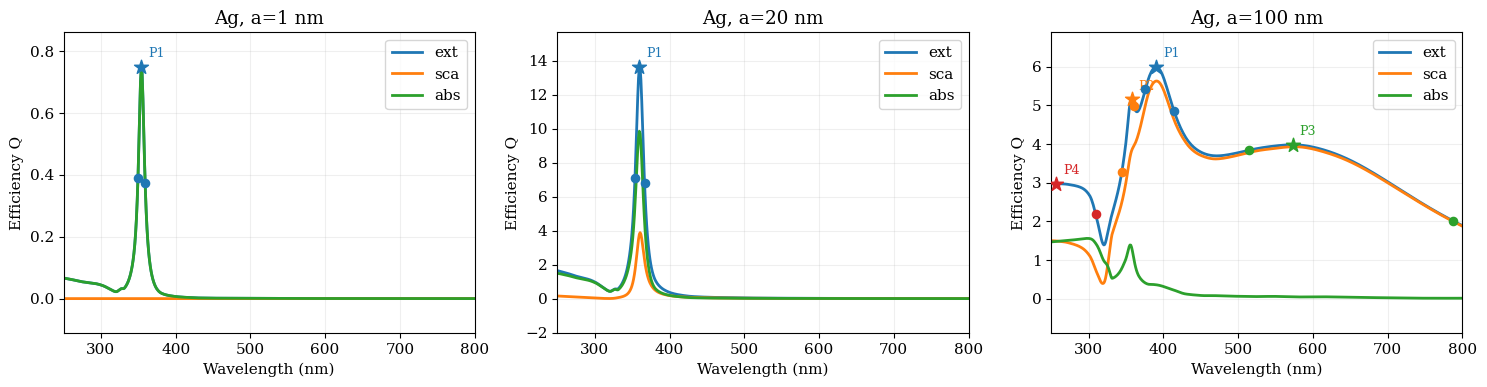

In [2]:
# More sensitive detection; independent of the earlier settings.
PEAK_PROMINENCE = 0.02
MAX_PEAKS = 6
PLOT_RANGE_NM = (250, 800) if MATERIAL == "Ag" else None

cases = {}
fig, axes = plt.subplots(
    1, len(RADII), figsize=(15, 4), squeeze=False
)

for ax, a in zip(axes.flat, RADII):
    s = spectrum(HC_EV_NM / wavelength, a, epsilon, NMAX)
    scheck = spectrum(HC_EV_NM / wavelength, a, epsilon, NMAX + 4)

    error = max(
        np.max(abs(s[k] - scheck[k]))
        / max(np.max(abs(scheck[k])), 1e-15)
        for k in ("ext", "sca", "abs")
    )
    if error > FIELD_TOL:
        raise RuntimeError(
            f"Increase NMAX: spectrum not converged for a={a:g} nm."
        )

    y = s[PEAK_KIND]
    peaks, _ = find_peaks(
        y, prominence=PEAK_PROMINENCE * y.max()
    )
    valleys, _ = find_peaks(-y)

    if not len(peaks):
        raise RuntimeError(
            f"No resolved peak for a={a:g}; adjust the scan range."
        )

    # Strongest first, preserving DECAY_PEAK_INDEX = 0 behavior.
    peaks = peaks[np.argsort(y[peaks])[::-1]]
    if len(peaks) > MAX_PEAKS:
        print(
            f"Warning: a={a:g} nm has {len(peaks)} detected peaks; "
            f"only the strongest {MAX_PEAKS} are selected."
        )
    peaks = peaks[:MAX_PEAKS]

    selected = []

    for p in peaks:
        # Nearest local minimum on each side.
        # Use the scan boundary if no minimum exists.
        vl = valleys[valleys < p]
        vr = valleys[valleys > p]
        left_bound = int(vl[-1]) if len(vl) else 0
        right_bound = int(vr[0]) if len(vr) else len(y) - 1

        def flank_wavelength(bound):
            # Walk outward from the peak toward this side's valley.
            step = 1 if bound > p else -1
            idx = np.arange(p, bound + step, step)

            # Half of the drop to THIS side's valley:
            # the two sides may have different target heights.
            target = 0.5 * (y[p] + y[bound])
            hits = np.flatnonzero(y[idx] <= target)

            if not len(hits) or hits[0] == 0:
                raise RuntimeError(
                    "Cannot resolve a flank; refine the wavelength grid."
                )

            j = hits[0]
            i0, i1 = idx[j - 1], idx[j]
            fraction = (target - y[i0]) / (y[i1] - y[i0])

            return (
                wavelength[i0]
                + fraction * (wavelength[i1] - wavelength[i0])
            )

        triplet = np.array([
            flank_wavelength(left_bound),
            wavelength[p],
            flank_wavelength(right_bound),
        ])
        selected.append(triplet)

    cases[a] = {"spectrum": s, "selected": selected}

    for k in ("ext", "sca", "abs"):
        ax.plot(wavelength, s[k], label=k)

    # A distinct color for each peak's three selected wavelengths.
    for j, triplet in enumerate(selected):
        color = plt.get_cmap("tab10")(j % 10)
        heights = np.interp(triplet, wavelength, y)

        ax.scatter(
            triplet[[0, 2]], heights[[0, 2]],
            color=color, marker="o", s=35, zorder=5
        )
        ax.scatter(
            triplet[1], heights[1],
            color=color, marker="*", s=110, zorder=6
        )
        ax.annotate(
            f"P{j + 1}", (triplet[1], heights[1]),
            xytext=(5, 7), textcoords="offset points",
            color=color, fontsize=9
        )

        print(
            f"a={a:g} nm, P{j + 1}: "
            f"blue / peak / red = {triplet.round(3)} nm"
        )

    if max(y[0], y[-1]) > 0.8 * y.max():
        print(
            f"Warning: substantial response at scan boundary "
            f"for a={a:g} nm."
        )

    ax.set(
        title=f"{MATERIAL}, a={a:g} nm",
        xlabel="Wavelength (nm)",
        ylabel="Efficiency Q",
    )
    if PLOT_RANGE_NM is not None:
        ax.set_xlim(*PLOT_RANGE_NM)

    ax.margins(y=0.15)
    ax.legend()
    ax.grid(alpha=0.2)

fig.tight_layout()
savefig(fig, "01_spectra")
plt.show()

## 2. Surface cross-sections
Sample $x=r\sin\theta$, $z=r\cos\theta$, with $r=a(1+\delta)$ just outside the sphere. The angle runs around the entire xz circumference. The maximum reported below is a **maximum on this circumference**, not a claimed global surface maximum.

Every field evaluation compares complex field components at $N$ and $N+4$; it raises an error if their normalized difference exceeds the tolerance.

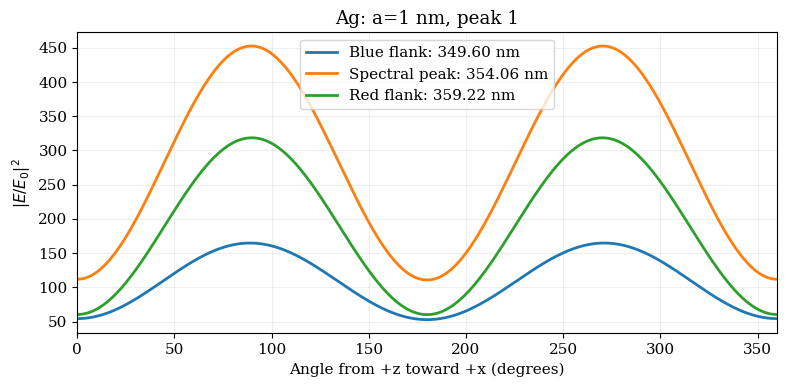

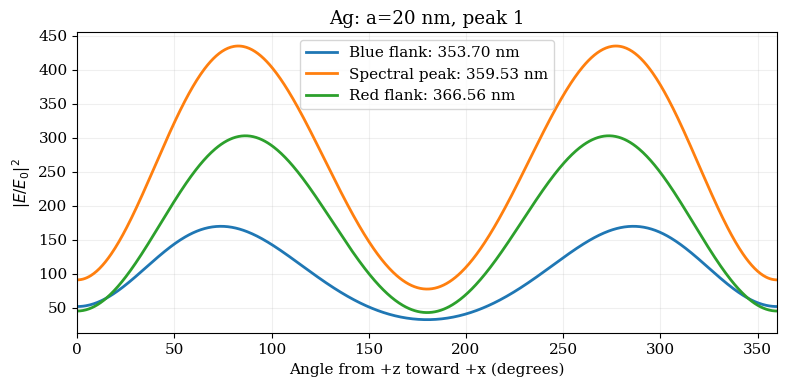

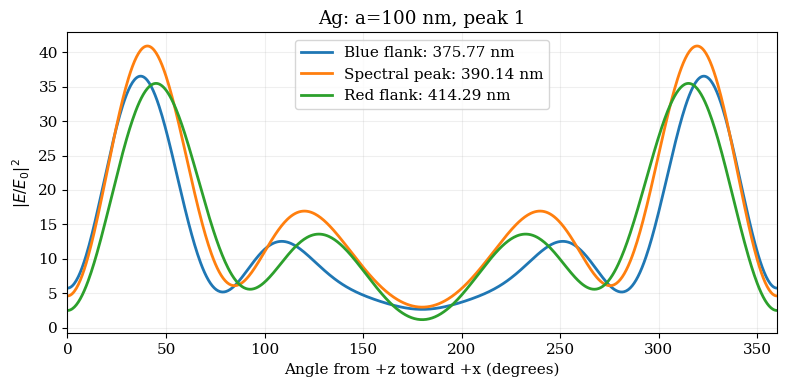

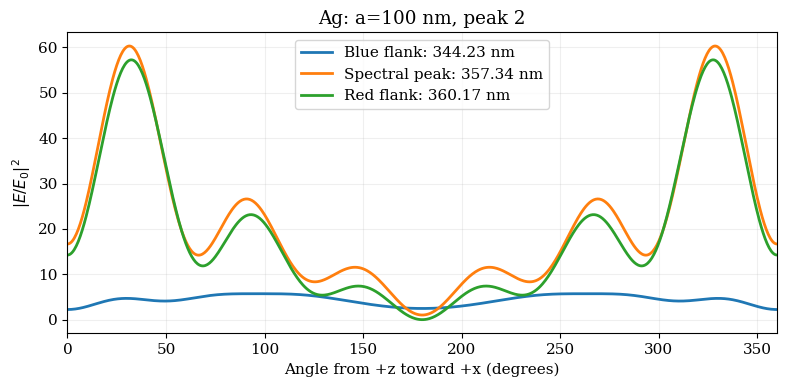

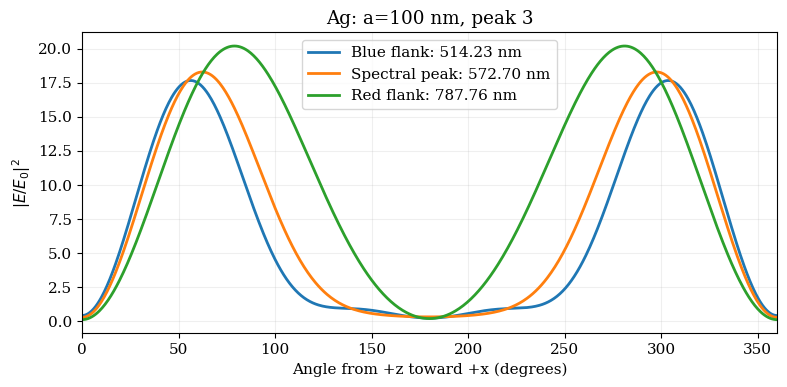

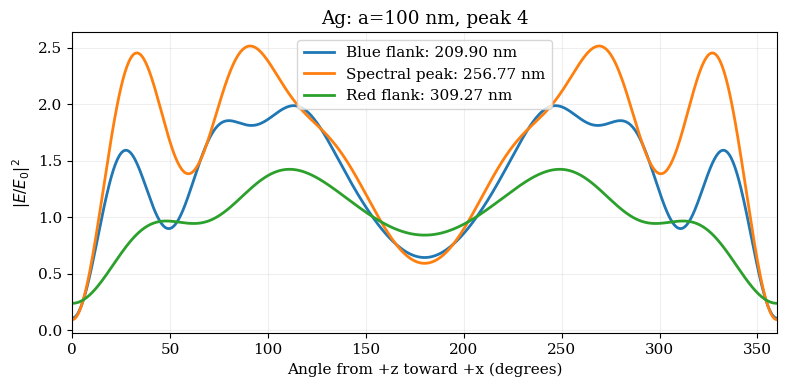

{'radius_nm': 1.0, 'peak': 1, 'position': 'Blue flank', 'wavelength_nm': 349.60088217071836, 'max_eta': 164.8222779166409, 'angle_deg': 89.0}
{'radius_nm': 1.0, 'peak': 1, 'position': 'Spectral peak', 'wavelength_nm': 354.06450000080997, 'max_eta': 452.56908230259126, 'angle_deg': 89.5}
{'radius_nm': 1.0, 'peak': 1, 'position': 'Red flank', 'wavelength_nm': 359.2222140959239, 'max_eta': 318.52092338000926, 'angle_deg': 90.0}
{'radius_nm': 20.0, 'peak': 1, 'position': 'Blue flank', 'wavelength_nm': 353.69774156897734, 'max_eta': 170.1008791645751, 'angle_deg': 74.0}
{'radius_nm': 20.0, 'peak': 1, 'position': 'Spectral peak', 'wavelength_nm': 359.5304375008037, 'max_eta': 435.2386625916123, 'angle_deg': 83.0}
{'radius_nm': 20.0, 'peak': 1, 'position': 'Red flank', 'wavelength_nm': 366.5637705959505, 'max_eta': 303.19645555526324, 'angle_deg': 86.5}
{'radius_nm': 100.0, 'peak': 1, 'position': 'Blue flank', 'wavelength_nm': 375.77012955277655, 'max_eta': 36.52990513877061, 'angle_deg': 37.

In [3]:
def checked_field(x, z, a, lam):
    args = (x, z, HC_EV_NM/lam, a, complex(eps_at(lam)))
    f = electric_field_xz(*args, NMAX)
    g = electric_field_xz(*args, NMAX+4)
    scale = max(1., float(np.max(np.sqrt(abs(g[0])**2+abs(g[1])**2))))
    err = max(float(np.max(abs(f[i]-g[i]))) for i in (0,1))/scale
    if not np.isfinite(err) or err > FIELD_TOL:
        raise RuntimeError(f'Field convergence failed: {err:.3g}; increase NMAX')
    return g

def eta_at(x, z, a, lam):
    ex, ez, _, _ = checked_field(x, z, a, lam)
    return abs(ex)**2 + abs(ez)**2

theta = np.linspace(0, 2*np.pi, N_ANGLE)
rows = []
for a in RADII:
    for j, triplet in enumerate(cases[a]['selected']):
        fig, ax = plt.subplots(figsize=(8,4))
        r = a*(1+SURFACE_OFFSET)
        for label, lam in zip(('Blue flank','Spectral peak','Red flank'), triplet):
            eta = eta_at(r*np.sin(theta), r*np.cos(theta), a, lam)
            # Verify the exterior-surface offset is negligible.
            r2 = a*(1+SURFACE_OFFSET/10)
            eta2 = eta_at(r2*np.sin(theta), r2*np.cos(theta), a, lam)
            err = np.max(abs(eta-eta2))/max(1., eta2.max())
            if err > 1e-3: raise RuntimeError('Decrease SURFACE_OFFSET')
            ax.plot(np.degrees(theta), eta, label=f'{label}: {lam:.2f} nm')
            idx = int(np.argmax(eta))
            rows.append(dict(radius_nm=a, peak=j+1, position=label,
                             wavelength_nm=float(lam), max_eta=float(eta[idx]),
                             angle_deg=float(np.degrees(theta[idx]))))
            if SAVE: np.savetxt(OUT/f'surface_a{a:g}_peak{j+1}_{label.replace(" ","_")}.csv',
                               np.c_[np.degrees(theta),eta], delimiter=',',
                               header='angle_deg,eta', comments='')
        ax.set(xlabel='Angle from +z toward +x (degrees)', ylabel=r'$|E/E_0|^2$',
               title=f'{MATERIAL}: a={a:g} nm, peak {j+1}', xlim=(0,360))
        ax.legend(); ax.grid(alpha=.2); fig.tight_layout()
        savefig(fig, f'02_surface_a{a:g}_peak{j+1}'); plt.show()
for row in rows: print(row)

## 3. Outward distance dependence
Choose the strongest sampled surface direction at the selected spectral peak and keep that direction fixed as distance increases. The total field approaches the incident field, so $\eta\to1$. The scattered-only quantity is also shown to distinguish decay from incident/scattered interference. A pure $r^{-6}$ intensity law is only a quasistatic dipole near-field limit, not a universal fit to the total field.

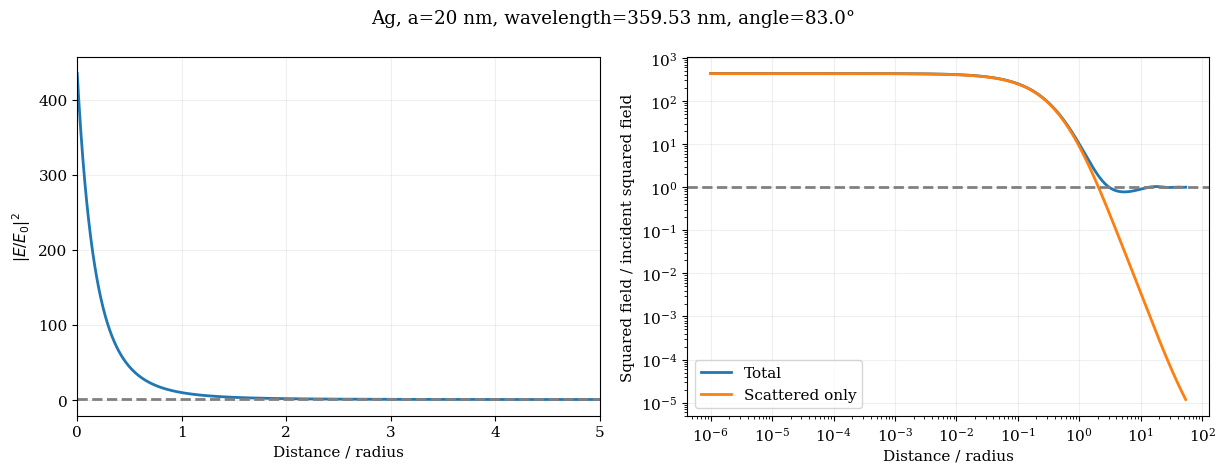

In [4]:
a = DECAY_RADIUS
lam = cases[a]['selected'][DECAY_PEAK_INDEX][1]
r = a*(1+SURFACE_OFFSET)
surface = eta_at(r*np.sin(theta), r*np.cos(theta), a, lam)
angle = theta[np.argmax(surface)]
distance = np.r_[a*SURFACE_OFFSET, np.geomspace(max(a*SURFACE_OFFSET*2, a*1e-5), max(20*a, 3*lam), 650)]
r = a+distance
ex, ez, sx, sz = checked_field(r*np.sin(angle), r*np.cos(angle), a, lam)
eta = abs(ex)**2+abs(ez)**2
scattered = abs(sx)**2+abs(sz)**2
fig, axes = plt.subplots(1,2,figsize=(12.4,4.8))
axes[0].plot(distance/a, eta); axes[0].axhline(1,color='gray',ls='--')
axes[0].set(xlabel='Distance / radius', ylabel=r'$|E/E_0|^2$', xlim=(0,5))
axes[1].loglog(distance/a, eta,label='Total')
axes[1].loglog(distance/a, scattered,label='Scattered only')
axes[1].axhline(1,color='gray',ls='--'); axes[1].legend()
axes[1].set(xlabel='Distance / radius', ylabel='Squared field / incident squared field')
for ax in axes: ax.grid(alpha=.2)
fig.suptitle(f'{MATERIAL}, a={a:g} nm, wavelength={lam:.2f} nm, angle={np.degrees(angle):.1f}°')
fig.tight_layout(); savefig(fig,'03_decay'); plt.show()
if SAVE:
    np.savetxt(OUT/'decay.csv', np.c_[distance,distance/a,eta,scattered],delimiter=',',
               header='distance_nm,distance_over_radius,total_eta,scattered_eta',comments='')
    with (OUT/'surface_summary.csv').open('w',newline='') as f:
        w=csv.DictWriter(f,fieldnames=rows[0].keys()); w.writeheader(); w.writerows(rows)

## 4. Small-sphere consistency check
At the polarization pole of a small sphere in vacuum, the quasistatic exterior amplitude is $E_x/E_0=3\varepsilon/(\varepsilon+2)$. Compare this with the exact Mie field for the 1 nm sphere. A small nonzero difference is expected from retardation. This is a physics check, independent of multipole truncation checks.

In [5]:
a = 1.
lam = cases[a]['selected'][0][1]
eps = complex(eps_at(lam))
ex, ez, _, _ = checked_field(np.array([a*(1+SURFACE_OFFSET)]), np.array([0.]), a, lam)
quasistatic = 3*eps/(eps+2)
relative_difference = abs(ex[0]-quasistatic)/abs(quasistatic)
print(f'1 nm pole: Mie eta={abs(ex[0])**2+abs(ez[0])**2:.6g}, QS eta={abs(quasistatic)**2:.6g}')
print(f'Complex-amplitude relative difference: {relative_difference:.3%}')
if relative_difference > .05:
    print('Review wavelength/size regime: quasistatic agreement is worse than 5%.')
print('Outputs:', OUT.resolve() if SAVE else 'Saving disabled')

1 nm pole: Mie eta=452.552, QS eta=452.425
Complex-amplitude relative difference: 0.266%
Outputs: C:\Users\perez\OneDrive\Documentos\RICE\ROTATIONS\Nordlander\HW5_Mie\HW5_Mie_single\results_hw6
